In [1]:
import os

corpus = []      # texts
file_names = []  # file name of every text, in the same order

data_folder = os.path.join(os.getcwd(), "..", "data", "corpus")
for file in sorted(os.listdir(data_folder)):  # sorted: same order on every computer
    with open(os.path.join(data_folder, file), encoding="utf8") as f:
        corpus.append(f.read())
    file_names.append(file)

print(len(corpus), "Texte wurden erfolgreich in den Korpus geladen.")

36 Texte wurden erfolgreich in den Korpus geladen.


In [2]:
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re

corpus_list = []
#corpus_vec = []
corpus_name = []

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 * asw)
    
    return round(fre,2)

dic = pyphen.Pyphen(lang="de_DE")

def syllables(word):
    """Silben eines einzelnen Wortes."""
    return len(dic.inserted(word).split("-"))

def avg_syllables_per_word(text):
    words = re.findall(r"\b\w+\b", text.lower())
    return round(sum(syllables(w) for w in words) / len(words), 1)

def wiener_sachtext_formel(text):
    words = re.findall(r"\b\w+\b", text.lower())
    n = len(words)
    syl = [syllables(w) for w in words]            # Silben pro Wort

    ms = sum(s >= 3 for s in syl) / n * 100        # % Wörter mit 3 oder mehr Silben
    sl = avg_sen_len(text)                         # Wörter pro Satz
    iw = sum(len(w) > 6 for w in words) / n * 100  # % Wörter mit mehr als 6 Buchstaben
    es = sum(s == 1 for s in syl) / n * 100        # % einsilbige Wörter

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf, 2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



In [3]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #nltk_text_words = word_tokenize(text)
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)
    print(wordcount,sentencescount)

    avgsenlen = avg_sen_len(text) #average sentence length
    #print(avg_sen_len)
    avgwordlen = avg_word_len(text)
    #print(avg_word_len)
    #print(avgwordlen,avgsenlen)


    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg)
    print(ngram_haeufigkeit(text))

    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    #corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg])
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

#print("Corpuslist:",corpus_list)

33273 2121
5.8 15.7 1.9 9.1 0.21
Anzahl eindeutiger Bigramme: 28360
Anzahl eindeutiger Trigramme: 38031

Top 5 Bigramme:
(',', 'daß') → 218 Mal
('!', '“') → 200 Mal
(',', 'die') → 150 Mal
(',', 'der') → 125 Mal
('.', 'der') → 121 Mal

Top 5 Trigramme:
('!', '“', '„') → 65 Mal
(',', 'daß', 'der') → 46 Mal
('?', '“', '„') → 32 Mal
(',', 'daß', 'die') → 26 Mal
(',', 'daß', 'er') → 13 Mal
None
-----------------------------------------------
46210 3493
5.5 13.2 1.8 7.18 0.17
Anzahl eindeutiger Bigramme: 35582
Anzahl eindeutiger Trigramme: 50524

Top 5 Bigramme:
('!', '“') → 598 Mal
('“', '„') → 586 Mal
('.', '„') → 302 Mal
('?', '“') → 285 Mal
(',', 'daß') → 259 Mal

Top 5 Trigramme:
('!', '“', '„') → 312 Mal
('?', '“', '„') → 207 Mal
('“', '„', 'ich') → 44 Mal
(',', 'daß', 'der') → 38 Mal
('“', '„', 'ja') → 35 Mal
None
-----------------------------------------------
68255 3834
5.5 17.8 1.8 8.13 0.16
Anzahl eindeutiger Bigramme: 50867
Anzahl eindeutiger Trigramme: 73673

Top 5 Bigramme:
('!

# Support Vector Machine

In [4]:
# Load the important packages
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn import svm
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report
import sklearn.metrics as metrics

colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .', 'Avg ,', 'Avg ;', 'Avg :']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp["Author"] = [name.split("-")[0].capitalize() for name in file_names]
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,5.8,15.7,1.9,9.10,53.15,0.21,0.013,0.003,0.036,0.061,0.005,0.003,Achleitner
1,5.5,13.2,1.8,7.18,61.50,0.17,0.022,0.007,0.032,0.062,0.001,0.002,Achleitner
2,5.5,17.8,1.8,8.13,56.90,0.16,0.018,0.004,0.024,0.070,0.002,0.004,Achleitner
3,5.3,16.3,1.7,6.91,64.25,0.17,0.017,0.004,0.030,0.066,0.004,0.004,Achleitner
4,5.5,12.7,1.8,7.49,62.00,0.15,0.032,0.005,0.029,0.063,0.002,0.005,Achleitner
5,5.4,16.4,1.7,7.33,64.15,0.21,0.004,0.002,0.042,0.088,0.000,0.000,Anonymous
6,5.3,13.5,1.8,6.98,61.20,0.20,0.001,0.003,0.050,0.074,0.000,0.000,Anonymous
7,5.4,15.5,1.8,7.85,59.20,0.20,0.001,0.002,0.048,0.075,0.000,0.000,Anonymous
8,5.4,15.1,1.8,7.58,59.60,0.21,0.001,0.001,0.051,0.072,0.000,0.000,Anonymous
9,5.5,13.6,1.8,7.50,61.10,0.21,0.001,0.001,0.054,0.073,0.000,0.000,Anonymous


In [5]:
X = corp[colu] # Features
y = corp.Author # Target variable

In [6]:
X2 = X.drop(X.columns[2:], axis=1)
y2 = corp.iloc[:,12]

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_train, X_test, y_train, y_test = train_test_split(X2, y2, random_state=33, test_size=0.2)

pipe = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear"))])
param_grid = {"svm__C": [0.01, 0.1, 1, 10, 100]}
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy")
grid_search.fit(X_train, y_train)          # nur mit den Trainingsdaten
print("Bestes C:", grid_search.best_params_["svm__C"])
print(f"Accuracy in der Cross-Validation: {grid_search.best_score_:.2f}")

clf_fit = grid_search.best_estimator_      # bestes Modell, schon trainiert

Bestes C: 100
Accuracy in der Cross-Validation: 0.54


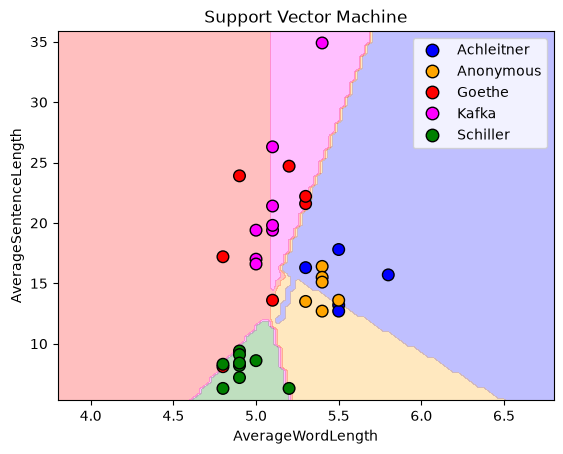

In [8]:
from matplotlib.lines import Line2D

colors = {"Achleitner": "#0000FF", "Anonymous": "#FFA500", "Goethe": "#FF0000",
          "Kafka": "#FF00FF", "Schiller": "#008000"}

disp = DecisionBoundaryDisplay.from_estimator(
    clf_fit, X2, response_method="predict", alpha=0.25,
    multiclass_colors=[colors[a] for a in clf_fit.classes_],  # Flächen in denselben Farben wie die Punkte
    xlabel=X2.columns[0], ylabel=X2.columns[1],               # Achsen direkt aus den Spalten
)
disp.ax_.scatter(X2.iloc[:, 0], X2.iloc[:, 1], c=y2.map(colors), s=70, edgecolors="k")
disp.ax_.legend(handles=[
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor=c, markeredgecolor="k", markersize=9, label=a)
    for a, c in colors.items()
])
disp.ax_.set_title("Support Vector Machine")
plt.show()

In [9]:
y_pred = clf_fit.predict(X_test)

In [10]:
accuracy = metrics.accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 25.00%


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       0.00      0.00      0.00         0
   Anonymous       0.00      0.00      0.00         2
      Goethe       0.00      0.00      0.00         1
       Kafka       0.50      0.50      0.50         2
    Schiller       1.00      0.33      0.50         3

    accuracy                           0.25         8
   macro avg       0.30      0.17      0.20         8
weighted avg       0.50      0.25      0.31         8



c:\workspace\german-authorship-attribution\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\workspace\german-authorship-attribution\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\workspace\german-authorship-attribution\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

### 10 Fold Cross Valdidation

In [12]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf_fit, X2, y2, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("\nAverage CV Score: ", scores.mean())
print("\nNumber of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.25       0.25       0.         0.25       0.         0.
 0.33333333 1.         0.33333333 1.        ]

Average CV Score:  0.3416666666666667

Number of CV Scores used in Average:  10


## Confusion Matrix

In [13]:
confusion_matrix(y_test, y_pred)

array([[0, 0, 0, 0, 0],
       [2, 0, 0, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 1, 1, 0],
       [0, 1, 1, 0, 1]])

In [14]:
df_cm = pd.DataFrame()
df_cm["True"] = y_test
df_cm["Predict"] = y_pred
df_cm

,True,Predict
17,Goethe,Kafka
8,Anonymous,Achleitner
32,Schiller,Goethe
5,Anonymous,Achleitner
21,Kafka,Goethe
22,Kafka,Kafka
31,Schiller,Schiller
30,Schiller,Anonymous


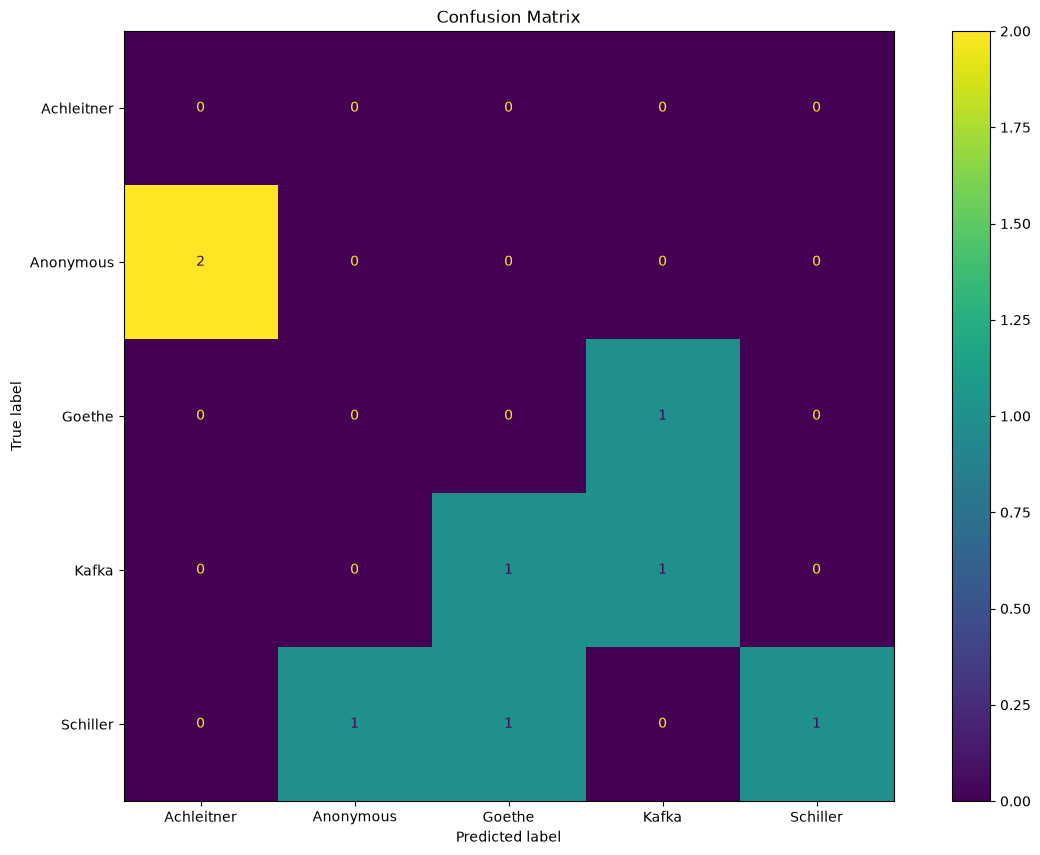

In [15]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(15, 10)
plt.title("Confusion Matrix")
plt.show()